In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1791269293.450394    9917 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791269293.601216    9917 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791269295.054930    9917 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
TRAIN_DIR = "/mnt/c/Users/sagni/EMO-Recognition/Datasets/train"
TEST_DIR = "/mnt/c/Users/sagni/EMO-Recognition/Datasets/test"


class_names = sorted(os.listdir(TRAIN_DIR))
NUM_CLASSES = len(class_names)

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of classes: 7


In [4]:
counts = pd.DataFrame({
    "train": [
        len(os.listdir(os.path.join(TRAIN_DIR, c)))
        for c in class_names
    ],
    "test": [
        len(os.listdir(os.path.join(TEST_DIR, c)))
        for c in class_names
    ]
}, index=class_names)

print(counts)

          train  test
angry      3995   958
disgust     436   111
fear       4097  1024
happy      7215  1774
neutral    4965  1233
sad        4830  1247
surprise   3171   831


In [5]:
BATCH = 64
VAL_SPLIT = 0.1

common = dict(
    labels="inferred",
    label_mode="categorical",
    color_mode="rgb",
    image_size=(48, 48),
    batch_size=None
)

raw_train = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=VAL_SPLIT,
    subset="training",
    seed=SEED,
    shuffle=True,
    **common
)

raw_val = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=VAL_SPLIT,
    subset="validation",
    seed=SEED,
    shuffle=True,
    **common
)

raw_test = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    shuffle=False,
    **common
)

Found 28709 files belonging to 7 classes.
Using 25839 files for training.


I0000 00:00:1791269378.180760    9917 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5378 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 28709 files belonging to 7 classes.
Using 2870 files for validation.
Found 7178 files belonging to 7 classes.


In [6]:
def prepare(ds, training=False):
    ds = ds.cache()

    if training:
        ds = ds.shuffle(5000, seed=SEED)

    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)


train_ds = prepare(raw_train, True)
val_ds = prepare(raw_val)
test_ds = prepare(raw_test)

In [7]:
n = counts["train"].values

cw = (n.sum() / (NUM_CLASSES * n)) ** 0.5

class_weight = {
    i: float(w)
    for i, w in enumerate(cw)
}

print({
    class_names[i]: round(w, 2)
    for i, w in class_weight.items()
})

{'angry': 1.01, 'disgust': 3.07, 'fear': 1.0, 'happy': 0.75, 'neutral': 0.91, 'sad': 0.92, 'surprise': 1.14}


In [8]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.15, value_range=(0, 255))
])

In [9]:
IMG_SIZE = 224

inp = keras.Input((48, 48, 3))

x = data_augmentation(inp)

x = layers.Resizing(IMG_SIZE, IMG_SIZE)(x)

x = keras.applications.vgg16.preprocess_input(x)

base = keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base.trainable = False

x = base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(256, activation="relu")(x)

x = layers.Dropout(0.5)(x)

out = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = keras.Model(inp, out)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 48, 48, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 48, 48, 3) │          0 │ input_layer[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing (Resizing) │ (None, 224, 224,  │          0 │ sequential[0][0]  │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ resizing[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ resizing[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ resizing[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    131,328 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 7)         │      1,799 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,847,815 (56.64 MB)

 Trainable params: 133,127 (520.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [10]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [11]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/12


/home/sagnik/miniconda3/envs/tf-gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791269408.470974   10003 cuda_dnn.cc:461] Loaded cuDNN version 92700
W0000 00:00:1791269409.609365   10003 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 3.08GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1791269409.609617   10003 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.55GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were avail

403/404 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - accuracy: 0.3203 - loss: 1.8026  

W0000 00:00:1791269491.846068    9999 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.60GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1791269491.846136    9999 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 3.51GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


404/404 ━━━━━━━━━━━━━━━━━━━━ 104s 231ms/step - accuracy: 0.3204 - loss: 1.8024 - val_accuracy: 0.4094 - val_loss: 1.5509 - learning_rate: 0.0010
Epoch 2/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 86s 212ms/step - accuracy: 0.3905 - loss: 1.5797 - val_accuracy: 0.4230 - val_loss: 1.4854 - learning_rate: 0.0010
Epoch 3/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 85s 211ms/step - accuracy: 0.4076 - loss: 1.5287 - val_accuracy: 0.4502 - val_loss: 1.4359 - learning_rate: 0.0010
Epoch 4/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 86s 212ms/step - accuracy: 0.4175 - loss: 1.5061 - val_accuracy: 0.4338 - val_loss: 1.4711 - learning_rate: 0.0010
Epoch 5/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 88s 218ms/step - accuracy: 0.4268 - loss: 1.4825 - val_accuracy: 0.4610 - val_loss: 1.4068 - learning_rate: 0.0010
Epoch 6/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 138s 208ms/step - accuracy: 0.4365 - loss: 1.4658 - val_accuracy: 0.4624 - val_loss: 1.3904 - learning_rate: 0.0010
Epoch 7/12
404/404 ━━━━━━━━━━━━━━━━━━━━ 86s 212ms/step - accuracy: 0.4365 - los

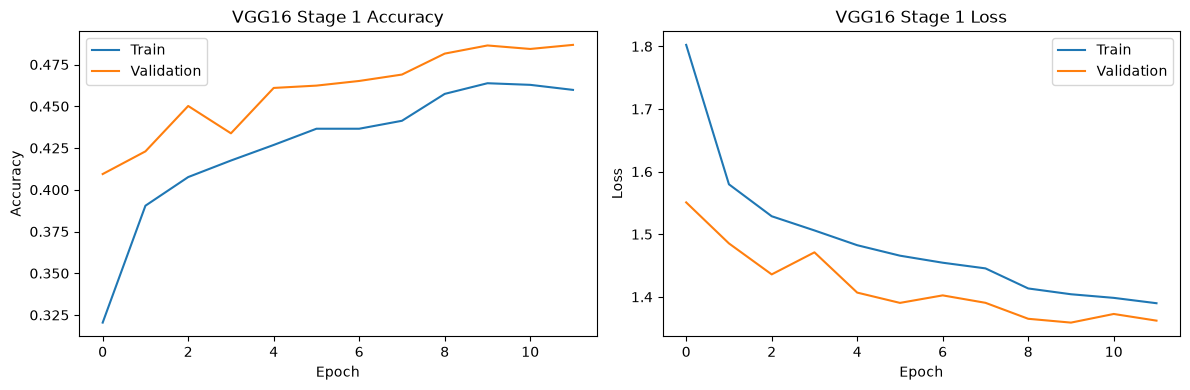

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history1.history["accuracy"], label="Train")
plt.plot(history1.history["val_accuracy"], label="Validation")
plt.title("VGG16 Stage 1 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history1.history["loss"], label="Train")
plt.plot(history1.history["val_loss"], label="Validation")
plt.title("VGG16 Stage 1 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
base.trainable = True

for layer in base.layers:
    layer.trainable = layer.name.startswith(
        ("block4", "block5")
    )

print("Trainable layers:")

for layer in base.layers:
    if layer.trainable:
        print(layer.name)

Trainable layers:
block4_conv1
block4_conv2
block4_conv3
block4_pool
block5_conv1
block5_conv2
block5_conv3
block5_pool


In [14]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [15]:
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/25


/home/sagnik/miniconda3/envs/tf-gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


404/404 ━━━━━━━━━━━━━━━━━━━━ 106s 252ms/step - accuracy: 0.4950 - loss: 1.3283 - val_accuracy: 0.5390 - val_loss: 1.2157 - learning_rate: 1.0000e-05
Epoch 2/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 99s 246ms/step - accuracy: 0.5310 - loss: 1.2303 - val_accuracy: 0.5700 - val_loss: 1.1334 - learning_rate: 1.0000e-05
Epoch 3/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 101s 251ms/step - accuracy: 0.5535 - loss: 1.1762 - val_accuracy: 0.5829 - val_loss: 1.0970 - learning_rate: 1.0000e-05
Epoch 4/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 102s 252ms/step - accuracy: 0.5682 - loss: 1.1343 - val_accuracy: 0.6000 - val_loss: 1.0575 - learning_rate: 1.0000e-05
Epoch 5/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 101s 249ms/step - accuracy: 0.5826 - loss: 1.0970 - val_accuracy: 0.6007 - val_loss: 1.0438 - learning_rate: 1.0000e-05
Epoch 6/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 102s 253ms/step - accuracy: 0.5935 - loss: 1.0600 - val_accuracy: 0.6059 - val_loss: 1.0472 - learning_rate: 1.0000e-05
Epoch 7/25
404/404 ━━━━━━━━━━━━━━━━━━━━ 105s 259ms/s

In [16]:
acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = history1.history["val_accuracy"] + history2.history["val_accuracy"]

loss = history1.history["loss"] + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]

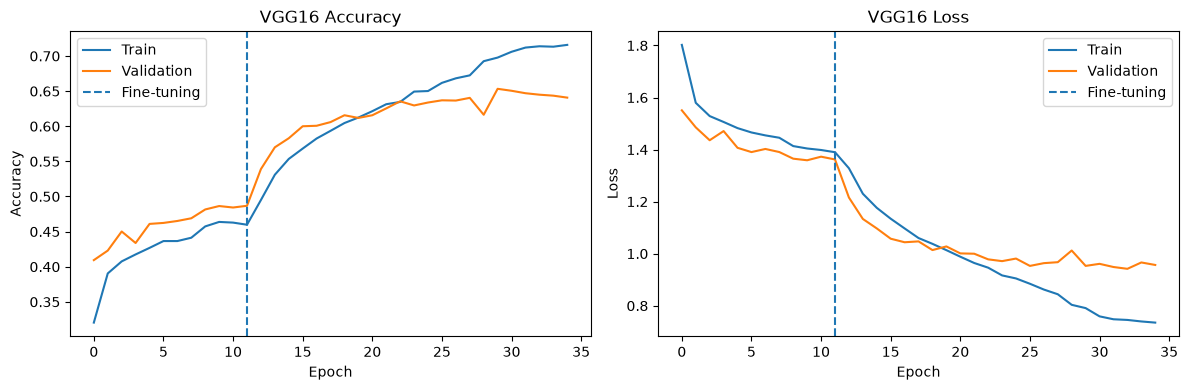

In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label="Train")
plt.plot(val_acc, label="Validation")
plt.axvline(
    len(history1.history["accuracy"]) - 1,
    linestyle="--",
    label="Fine-tuning"
)
plt.title("VGG16 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="Train")
plt.plot(val_loss, label="Validation")
plt.axvline(
    len(history1.history["loss"]) - 1,
    linestyle="--",
    label="Fine-tuning"
)
plt.title("VGG16 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
model.save("/mnt/c/Users/sagni/EMO-Recognition/Models/vgg16.keras")

In [19]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

113/113 ━━━━━━━━━━━━━━━━━━━━ 22s 196ms/step - accuracy: 0.6521 - loss: 0.9890
Test Loss: 0.9890157580375671
Test Accuracy: 0.6521314978599548


In [20]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(
        np.argmax(labels.numpy(), axis=1)
    )

    y_pred.extend(
        np.argmax(predictions, axis=1)
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

       angry       0.64      0.53      0.58       958
     disgust       0.74      0.58      0.65       111
        fear       0.50      0.37      0.42      1024
       happy       0.87      0.86      0.87      1774
     neutral       0.56      0.69      0.62      1233
         sad       0.50      0.54      0.52      1247
    surprise       0.74      0.82      0.78       831

    accuracy                           0.65      7178
   macro avg       0.65      0.63      0.63      7178
weighted avg       0.65      0.65      0.65      7178



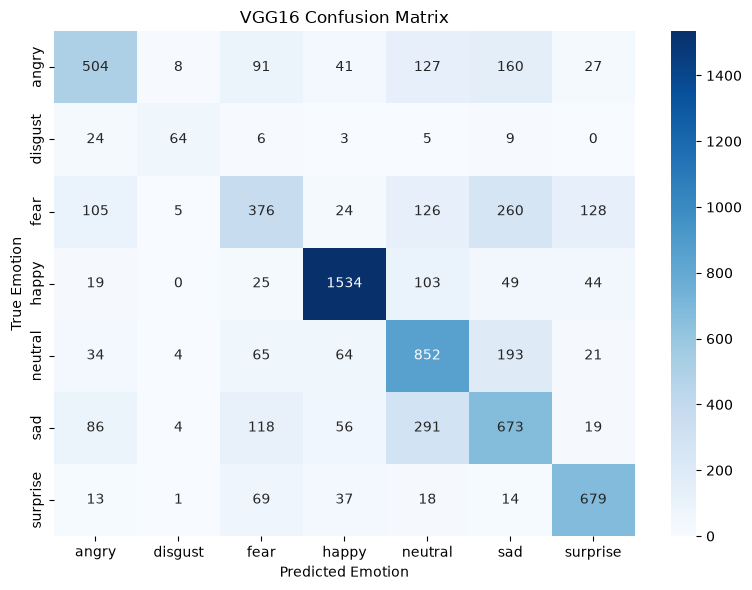

In [21]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.title("VGG16 Confusion Matrix")

plt.tight_layout()
plt.show()

In [22]:
comparison = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "ResNet50",
        "VGG16"
    ],

    "Test Accuracy": [
        0.6507383584976196,
        0.6720535159111023,
        test_accuracy
    ],

    "Macro F1": [
        0.62,
        0.66,
        0.63
    ]
})

comparison

,Model,Test Accuracy,Macro F1
0,Custom CNN,0.650738,0.62
1,ResNet50,0.672054,0.66
2,VGG16,0.652131,0.63


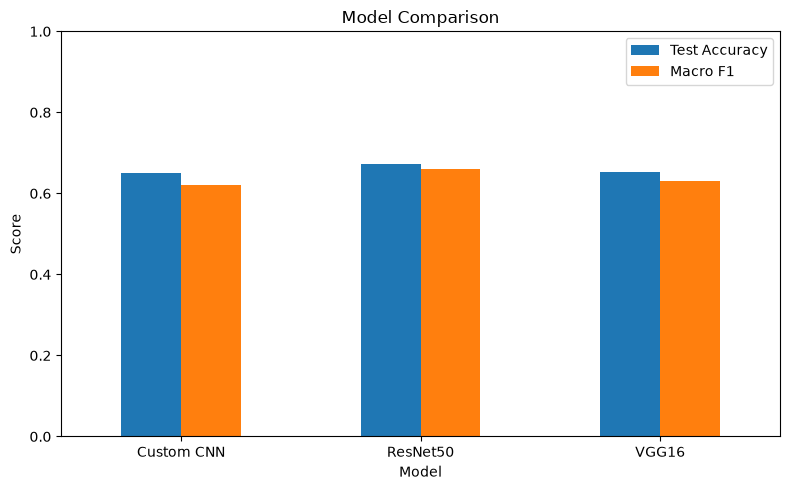

In [23]:
comparison.set_index("Model")[["Test Accuracy", "Macro F1"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Model Comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
import tensorflow as tf

model = tf.keras.models.load_model("/mnt/c/Users/sagni/EMO-Recognition/Models/resnet50.keras")

print(model.input_shape)
print(model.output_shape)
model.summary()

(None, 48, 48, 3)
(None, 7)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 48, 48, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 48, 48, 3) │          0 │ input_layer[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing (Resizing) │ (None, 224, 224,  │          0 │ sequential[0][0]  │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ resizing[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ resizing[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ resizing[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    524,544 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 7)         │      1,799 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 56,780,183 (216.60 MB)

 Trainable params: 16,333,063 (62.31 MB)

 Non-trainable params: 7,780,992 (29.68 MB)

 Optimizer params: 32,666,128 (124.61 MB)

In [26]:
print(class_names)

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
